# 04 - Model İyileştirme: Sınıf Ağırlığı ve Karar Eşiği

Aşama 3.1: Random Forest için `class_weight` ve karar eşiği denemesi. Tüm seçimler **validation** verisiyle yapılır; orijinal test kümesi en sonda yalnızca bir kez kullanılır.

> Not: AI4I 2020 sentetik bir veri setidir ve yalnızca 339 arıza örneği içerir. Sonuçlar deneyseldir; gerçek endüstriyel güvenilirlik veya arıza zamanı tahmini iddia edilmez.

## Kütüphaneler

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

pd.set_option("display.max_columns", None)

## Veri Setini Yükleme

In [2]:
# Notebook notebooks/ klasöründe çalışır; CSV UTF-8 BOM içerdiği için "utf-8-sig".
DATA_PATH = Path("../data/ai4i2020.csv")
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
df.shape

(10000, 14)

## Özellik ve Hedef Değişkenler

In [3]:
# Aşama 2 ve 3 ile birebir aynı 6 özellik ve hedef.
NUMERIC_FEATURES = [
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]",
]
CATEGORICAL_FEATURES = ["Type"]
FEATURES = CATEGORICAL_FEATURES + NUMERIC_FEATURES
TARGET = "Machine failure"

# Kimlikler ve arıza tipi etiketleri (arızadan sonra bilinir -> sızıntı) girdi olamaz.
EXCLUDED_COLUMNS = ["UDI", "Product ID", "TWF", "HDF", "PWF", "OSF", "RNF"]

X = df[FEATURES]
y = df[TARGET]

assert X.columns.tolist() == FEATURES
assert not (set(EXCLUDED_COLUMNS) | {TARGET}) & set(X.columns)
X.columns.tolist()

['Type',
 'Air temperature [K]',
 'Process temperature [K]',
 'Rotational speed [rpm]',
 'Torque [Nm]',
 'Tool wear [min]']

## İç İçe Veri Ayrımı (Train / Validation / Test)

In [4]:
# 1) Orijinal ayrım (Aşama 2-3 ile aynı): 8000 eğitim, 2000 test.
# Test kümesi tüm model ve eşik kararları bitene kadar KİLİTLİ kalır.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 2) Yalnızca 8000'lik eğitim kısmı ikiye bölünür: %75 iç eğitim, %25 validation.
# Adayları karşılaştırmak ve eşik seçmek için validation kullanılır.
X_inner, X_val, y_inner, y_val = train_test_split(
    X_train, y_train, test_size=0.25, random_state=42, stratify=y_train
)

# Kümeler birbiriyle çakışmamalı; inner + validation = orijinal eğitim kısmı.
assert not set(X_inner.index) & set(X_val.index)
assert not (set(X_inner.index) | set(X_val.index)) & set(X_test.index)
assert set(X_inner.index) | set(X_val.index) == set(X_train.index)

splits = {"inner train": y_inner, "validation": y_val, "full train": y_train, "test": y_test}
pd.DataFrame({
    "rows": {k: len(v) for k, v in splits.items()},
    "failures": {k: int(v.sum()) for k, v in splits.items()},
    "failure rate": {k: round(v.mean(), 4) for k, v in splits.items()},
})

,rows,failures,failure rate
inner train,6000,203,0.0338
validation,2000,68,0.0340
full train,8000,271,0.0339
test,2000,68,0.0340


## Aday Modeller

In [5]:
def make_rf(class_weight=None):
    # Aşama 3 ile aynı ön işleme: sayısal sütunlar olduğu gibi, Type one-hot.
    return Pipeline([
        ("preprocess", ColumnTransformer([
            ("num", "passthrough", NUMERIC_FEATURES),
            ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL_FEATURES),
        ])),
        ("classifier", RandomForestClassifier(random_state=42, class_weight=class_weight)),
    ])

# A: Aşama 3'teki orijinal Random Forest.
# B: Aynı model, class_weight="balanced" -> az olan arıza sınıfının hataları daha ağır cezalandırılır.
candidates = {
    "A: RF original": make_rf(),
    "B: RF balanced": make_rf(class_weight="balanced"),
}

In [6]:
# Adaylar YALNIZCA iç eğitim verisiyle (6000 satır) eğitilir.
# predict_proba(): validation kayıtları için arıza (sınıf 1) olasılığı.
val_proba = {}
for name, model in candidates.items():
    model.fit(X_inner, y_inner)
    val_proba[name] = model.predict_proba(X_val)[:, 1]

## Validation Değerlendirmesi

In [7]:
def evaluate(y_true, y_pred):
    # Arıza sınıfı (1) için metrikler; hiç '1' tahmini yoksa precision 0 kabul edilir.
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "TP": int(tp), "FP": int(fp), "TN": int(tn), "FN": int(fn),
    }

# Karar kuralı: arıza olasılığı >= eşik ise "arıza" (1) tahmini.
# Önceden belirlenmiş küçük eşik listesi; test kümesine hiç bakılmaz.
THRESHOLDS = [0.20, 0.30, 0.40, 0.50, 0.60]

rows = []
for name, proba in val_proba.items():
    for t in THRESHOLDS:
        y_pred = (proba >= t).astype(int)
        rows.append({"candidate": name, "threshold": t, **evaluate(y_val, y_pred)})

val_results = pd.DataFrame(rows)

In [8]:
# Önce varsayılan 0.5 eşiğinde iki adayın karşılaştırması.
val_results[val_results["threshold"] == 0.5].set_index("candidate").round(4)

,threshold,accuracy,precision,recall,f1,TP,FP,TN,FN
candidate,,,,,,,,,
A: RF original,0.5,0.9825,0.9714,0.5000,0.6602,34,1,1931,34
B: RF balanced,0.5,0.9720,0.5857,0.6029,0.5942,41,29,1903,27


In [9]:
# Tüm aday / eşik kombinasyonları (validation, 2000 satır, 68 arıza).
val_results[["candidate", "threshold", "precision", "recall", "f1", "FP", "FN"]].round(4)

,candidate,threshold,precision,recall,f1,FP,FN
0,A: RF original,0.2,0.4545,0.7353,0.5618,60,18
1,A: RF original,0.3,0.6812,0.6912,0.6861,22,21
2,A: RF original,0.4,0.8431,0.6324,0.7227,8,25
3,A: RF original,0.5,0.9714,0.5000,0.6602,1,34
4,A: RF original,0.6,0.9615,0.3676,0.5319,1,43
5,B: RF balanced,0.2,0.3182,0.8235,0.4590,120,12
6,B: RF balanced,0.3,0.4127,0.7647,0.5361,74,16
7,B: RF balanced,0.4,0.5281,0.6912,0.5987,42,21
8,B: RF balanced,0.5,0.5857,0.6029,0.5942,29,27
9,B: RF balanced,0.6,0.6875,0.4853,0.5690,15,35


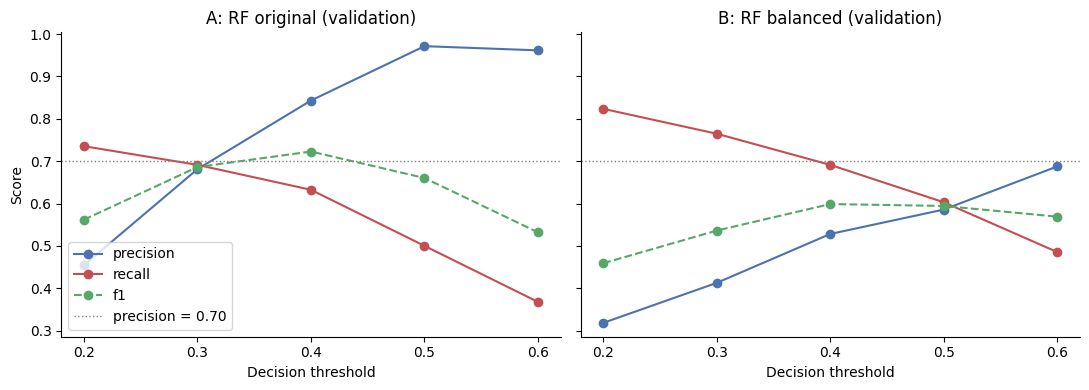

In [10]:
# Eşik düştükçe recall artar (daha çok arıza yakalanır), precision genelde düşer (daha çok yanlış alarm).
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (name, group) in zip(axes, val_results.groupby("candidate")):
    ax.plot(group["threshold"], group["precision"], marker="o", label="precision", color="#4C72B0")
    ax.plot(group["threshold"], group["recall"], marker="o", label="recall", color="#C44E52")
    ax.plot(group["threshold"], group["f1"], marker="o", linestyle="--", label="f1", color="#55A868")
    ax.axhline(0.70, color="gray", linestyle=":", linewidth=1, label="precision = 0.70")
    ax.set_title(f"{name} (validation)")
    ax.set_xlabel("Decision threshold")
    ax.set_xticks(THRESHOLDS)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Score")
axes[0].legend(loc="lower left")
fig.tight_layout()
plt.show()

## Final Konfigürasyon Seçimi (yalnızca validation)

In [11]:
# Seçim kuralı (yalnızca validation sonuçları):
# 1) precision >= 0.70 olanlar uygun sayılır.
# 2) Uygunlar arasında en yüksek recall, eşitlikte en yüksek F1.
# 3) Hâlâ eşitse daha yüksek eşik (daha az alarm), sonra aday adı (A önce) -> deterministik.
MIN_PRECISION = 0.70

qualifying = val_results[val_results["precision"] >= MIN_PRECISION]
if len(qualifying) > 0:
    ranked = qualifying.sort_values(
        ["recall", "f1", "threshold", "candidate"], ascending=[False, False, False, True]
    )
    requirement_met = True
else:
    # Hiçbiri uygun değilse en yüksek F1 seçilir ve bu durum açıkça raporlanır.
    ranked = val_results.sort_values(
        ["f1", "threshold", "candidate"], ascending=[False, False, True]
    )
    requirement_met = False

selected = ranked.iloc[0]
SELECTED_CANDIDATE = selected["candidate"]
SELECTED_THRESHOLD = float(selected["threshold"])

print("Precision >= 0.70 şartı sağlandı mı:", requirement_met)
print("Uygun kombinasyon sayısı:", len(qualifying), "/", len(val_results))
print("Seçilen aday:", SELECTED_CANDIDATE)
print("Seçilen eşik:", SELECTED_THRESHOLD)
ranked[["candidate", "threshold", "precision", "recall", "f1", "FP", "FN"]].head(5).round(4)

Precision >= 0.70 şartı sağlandı mı: True
Uygun kombinasyon sayısı: 3 / 10
Seçilen aday: A: RF original
Seçilen eşik: 0.4


,candidate,threshold,precision,recall,f1,FP,FN
2,A: RF original,0.4,0.8431,0.6324,0.7227,8,25
3,A: RF original,0.5,0.9714,0.5000,0.6602,1,34
4,A: RF original,0.6,0.9615,0.3676,0.5319,1,43


## Final Eğitim ve Tek Seferlik Test

In [12]:
# Seçilen konfigürasyonun temiz bir kopyası tüm 8000 satırlık orijinal eğitim kısmıyla yeniden eğitilir.
final_model = clone(candidates[SELECTED_CANDIDATE])
final_model.fit(X_train, y_train)

# Validation'da seçilen eşik DEĞİŞTİRİLMEDEN, kilitli test kümesine tek sefer uygulanır.
test_proba = final_model.predict_proba(X_test)[:, 1]
y_pred_final = (test_proba >= SELECTED_THRESHOLD).astype(int)

assert len(y_pred_final) == len(y_test) == 2000
assert set(pd.unique(y_pred_final)) <= {0, 1}

final_metrics = evaluate(y_test, y_pred_final)
pd.Series(final_metrics).round(4).to_frame(f"{SELECTED_CANDIDATE} @ {SELECTED_THRESHOLD}")

,A: RF original @ 0.4
accuracy,0.9830
precision,0.8269
recall,0.6324
f1,0.7167
TP,43.0000
FP,9.0000
TN,1923.0000
FN,25.0000


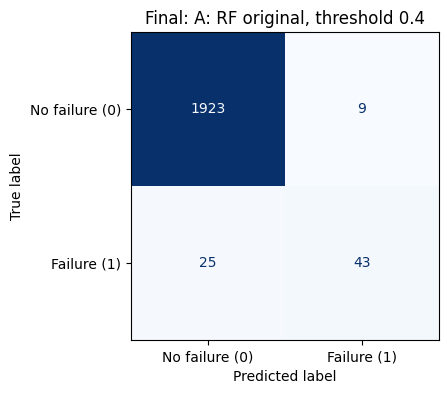

In [13]:
# Final confusion matrix (test kümesi).
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay(
    confusion_matrix(y_test, y_pred_final),
    display_labels=["No failure (0)", "Failure (1)"],
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title(f"Final: {SELECTED_CANDIDATE}, threshold {SELECTED_THRESHOLD}")
plt.show()

## Aşama 3 Baseline ile Karşılaştırma

In [14]:
# Bilgi amaçlı: Aşama 3'teki orijinal RF (8000 satırda eğitim, predict() ile varsayılan karar).
# Bu test sonuçları seçimde KULLANILMADI; seçim yukarıda validation ile yapıldı.
baseline_model = make_rf()
baseline_model.fit(X_train, y_train)
baseline_metrics = evaluate(y_test, baseline_model.predict(X_test))

# Aşama 3 raporu ile aynı olmalı: TP=34, FP=4, TN=1928, FN=34.
assert (baseline_metrics["TP"], baseline_metrics["FP"],
        baseline_metrics["TN"], baseline_metrics["FN"]) == (34, 4, 1928, 34)

final_vs_baseline = pd.DataFrame({
    "Stage 3 baseline (RF original, predict)": baseline_metrics,
    f"Stage 3.1 final ({SELECTED_CANDIDATE}, threshold {SELECTED_THRESHOLD})": final_metrics,
}).T
final_vs_baseline[["TP", "FP", "TN", "FN"]] = final_vs_baseline[["TP", "FP", "TN", "FN"]].astype(int)
final_vs_baseline.round(4)

,accuracy,precision,recall,f1,TP,FP,TN,FN
"Stage 3 baseline (RF original, predict)",0.981,0.8947,0.5000,0.6415,34,4,1928,34
"Stage 3.1 final (A: RF original, threshold 0.4)",0.983,0.8269,0.6324,0.7167,43,9,1923,25
